<a href="https://colab.research.google.com/github/A-I-eXplorers/ShimSoen/blob/main/Data_Preprocessing/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **와인 데이터 전처리 과정**

In [2]:
from sklearn.datasets import load_wine

wine = load_wine() # 데이터 불러오기

bunch 객체로 불러와 딕셔너리 유사 형태로 받아옴

In [3]:
x, y = wine.data, wine.target
print(x.shape, y.shape)
print(wine.feature_names)
print(wine.target_names)

(178, 13) (178,)
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
['class_0' 'class_1' 'class_2']


In [5]:
df = load_wine(as_frame=True).frame
print(df.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

pandas dataframe으로 받아와 eda와 시각화를 하기 위해 불러옴

# datatype 확인

In [6]:
print(df.dtypes)

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


# 결측치 확인

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

# 통계량 및 이상치 확인

In [8]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


평균적으로는 10-20 사이에 있지만 malic_acid, total_phenols 등 몇개는 0-1 값이고 proline은 수백-수천 사이의 값이라 차이가 크다는 걸 알 수 있음.

In [9]:
df['target'].value_counts()

,count
target,
1,71
0,59
2,48


wine의 품종의 데이터 개수가 균형 잡혀 있는지 확인

# 변수 간 관계 확인

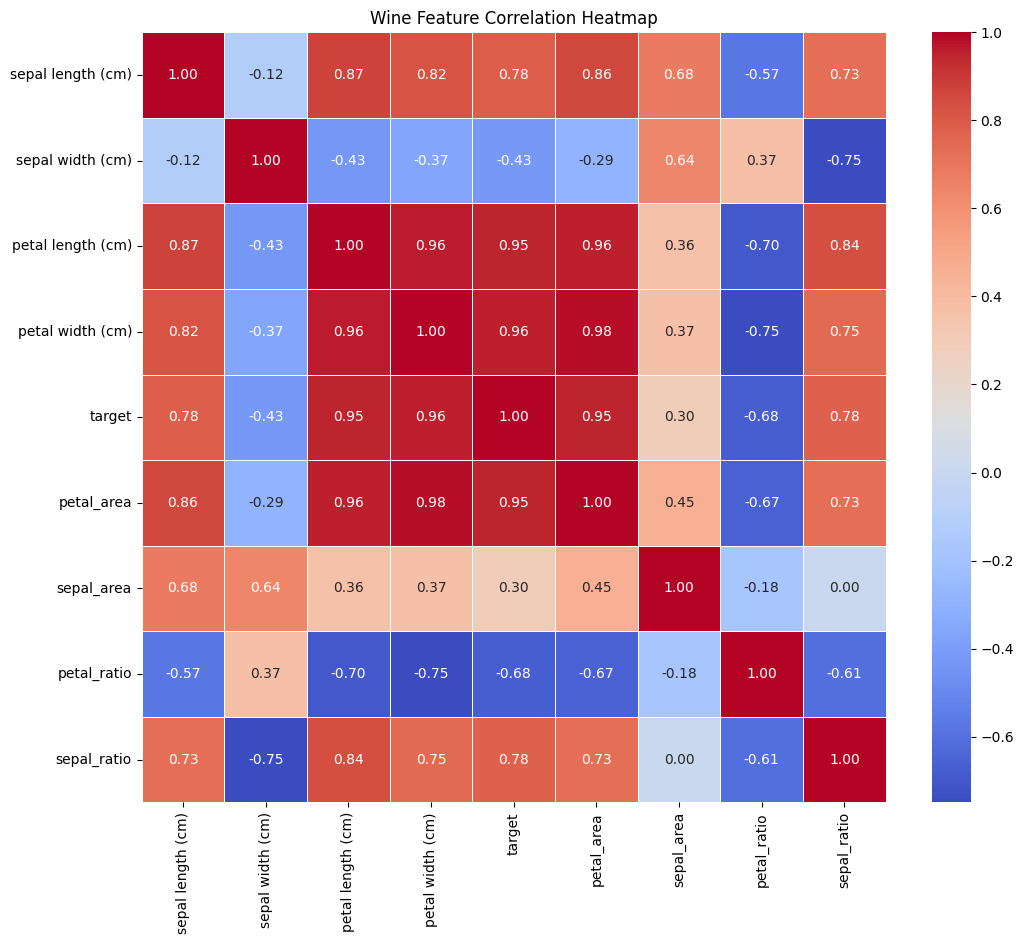

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Wine Feature Correlation Heatmap')
plt.show()

어떤 성분끼리 상관관계가 높은지 확인.

flavanoids와 total_phenols는 양의 상관관계가 높음

<Axes: xlabel='target', ylabel='alcohol'>

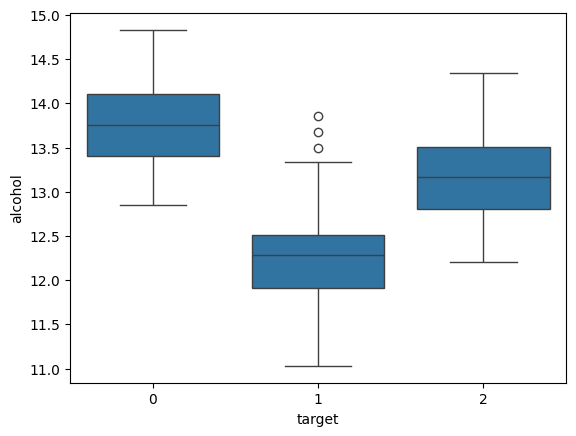

In [11]:
sns.boxplot(x='target', y='alcohol', data=df)

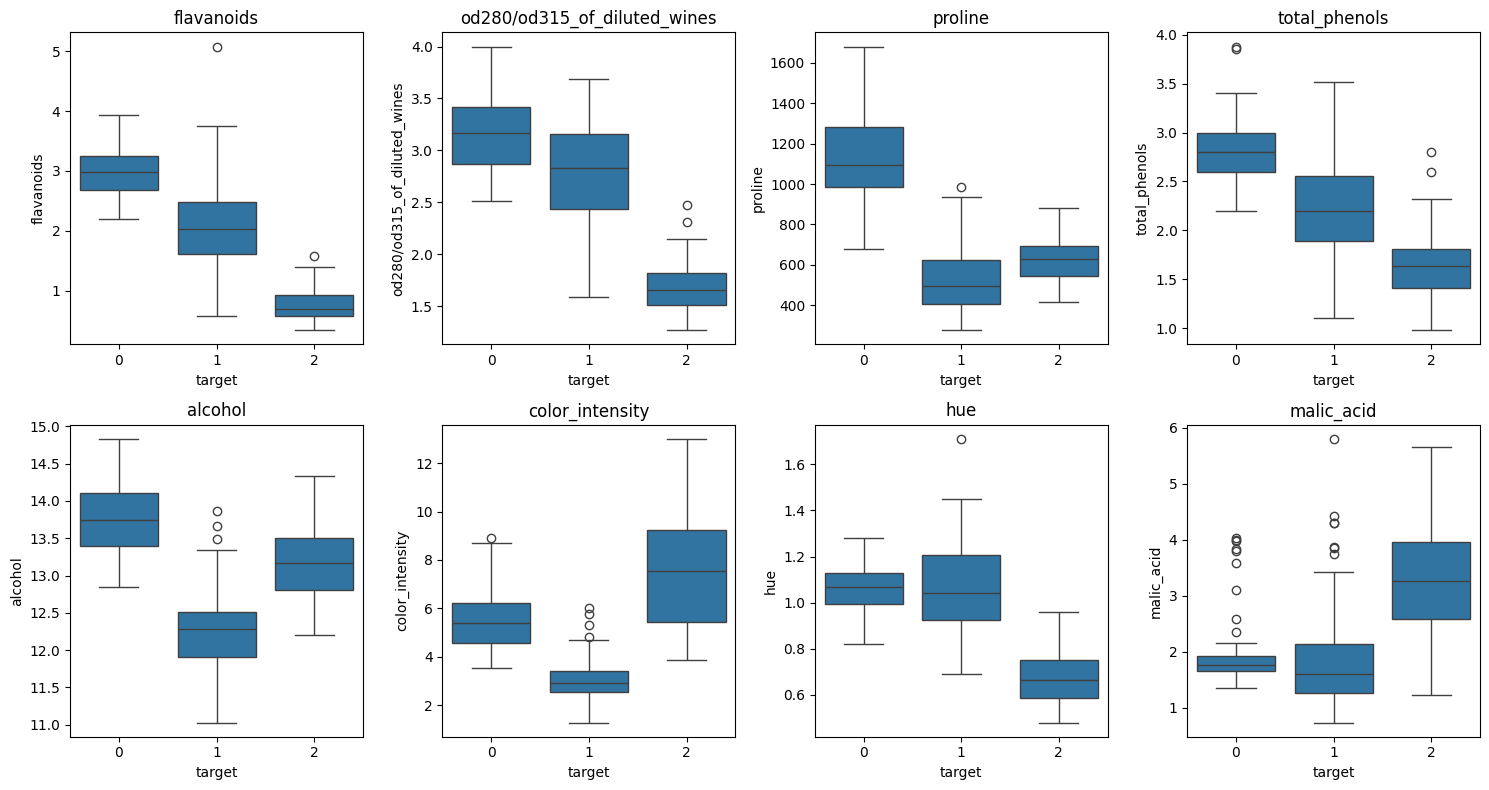

In [12]:
import matplotlib.pyplot as plt

key_features = [
    'flavanoids',
    'od280/od315_of_diluted_wines',
    'proline',
    'total_phenols',
    'alcohol',
    'color_intensity',
    'hue',
    'malic_acid'
]

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for idx, col in enumerate(key_features):
  row, c = divmod(idx, 4)
  sns.boxplot(x='target', y=col, data=df, ax=axes[row, c])
  axes[row, c].set_title(col)

plt.tight_layout()
plt.show()

앞선 상관계수에 따라 품종 구분에 가장 결정적인 변수 (flavanoids, od280/od315_of_diluted_wines, proline, total_phenols)과 감각적 특성(alcohol, color_intensity, malic_acid, hue) 사용


**품종 구분에 가장 결정적인 변수**
*   flavanoids: 플라보노이드, 떫은맛과 항산화 성분
*   od280/od315_of_diluted_wines: 희석 와인의 흡광도 / 와인의 농도 및 숙성도 지표
*   proline: 아미노산의 일종, 감칠맛과 바디감
*   total_phenols: 총 페놀 함량, 떫은맛과 바디감


**감각적 특성**
*   alcohol: 알코올
*   color_intensity: 색의 강도
*   hue: 색조 / 빛깔
*   malic_acid: 산미(사과산)



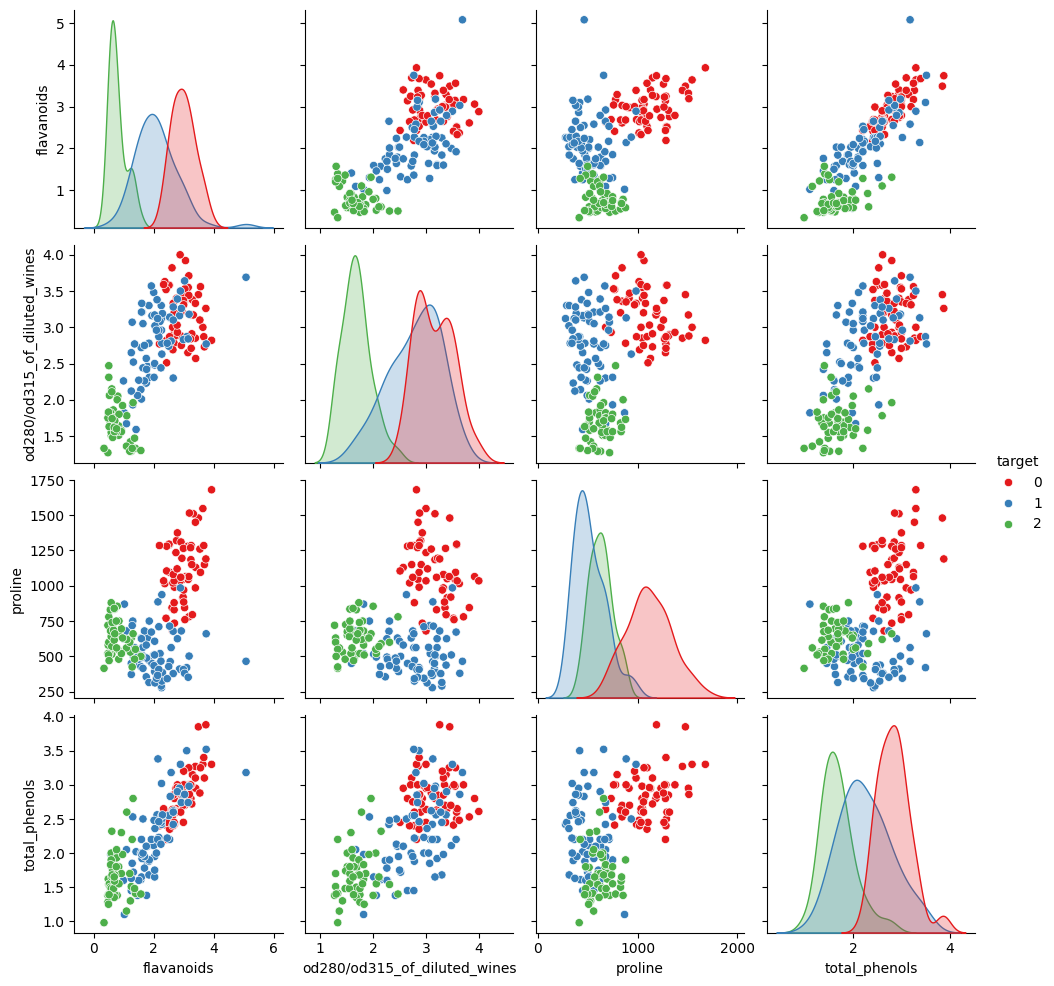

In [13]:
pairplot_cols = [
    'flavanoids',
    'od280/od315_of_diluted_wines',
    'proline',
    'total_phenols',
    'target'
]

sns.pairplot(df[pairplot_cols], hue='target', palette='Set1')
plt.show()

산점도 보면 각 품종이 섞여있기보단 군집을 형성하고 있음을 볼 수 있음

빨간색(class0)이 가장 높은 수치를 보임
초록색(class2)이 가장 낮은 수치를 보임
파란색(class1)은 초록색과 빨간색의 중간에 위치

산점도를 보면 어느 class에 이상치가 어떻게 있는지 확인

# 데이터 분할

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

In [15]:
x_train_mean = x_train.mean(axis=0)
x_train_std = x_train.std(axis=0)
x_train_s = (x_train - x_train_mean) / x_train_std
x_val_s = (x_val - x_train_mean) / x_train_std

print('특성별 평균: ', x_train_s.mean(axis=0).round(2))
print('특성별 표준편차: ', x_train_s.std(axis=0).round(2))

특성별 평균:  [ 0. -0.  0.  0.  0. -0.  0. -0. -0.  0. -0.  0. -0.]
특성별 표준편차:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# 주성분분석(PCA)

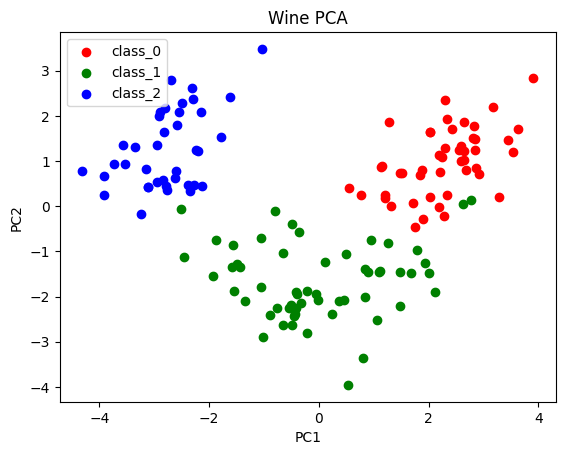

설명된 분산 비율: [0.358 0.193]
총 설명력: 0.551


In [16]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X2D = pca.fit_transform(x_train_s)

colors = ['red', 'green', 'blue']
for i, j in enumerate(np.unique(y_train)):
  plt.scatter(X2D[y_train == j, 0], X2D[y_train == j, 1],
              color = colors[i], label = f'class_{j}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine PCA')
plt.legend()
plt.show()

print('설명된 분산 비율:', pca.explained_variance_ratio_.round(3))
print('총 설명력:', pca.explained_variance_ratio_.sum().round(3))

In [17]:
import pandas as pd

loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=wine.feature_names
)

print(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).round(3))

                                PC1    PC2
flavanoids                    0.430 -0.003
total_phenols                 0.394  0.076
od280/od315_of_diluted_wines  0.383 -0.170
proanthocyanins               0.313  0.011
hue                           0.297 -0.298
nonflavanoid_phenols         -0.291  0.021
proline                       0.290  0.358
malic_acid                   -0.234  0.223
alcalinity_of_ash            -0.224 -0.039
magnesium                     0.152  0.296
alcohol                       0.144  0.487
color_intensity              -0.096  0.524
ash                           0.007  0.312


# **Iris 데이터셋**

In [18]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()
df = load_iris(as_frame=True).frame

# 결측치 확인

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


# 각 변수의 단위 확인



In [20]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


# 데이터 분할

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    iris.data, iris.target, test_size=0.2, stratify=iris.target, random_state=42
)

In [22]:
X_train_mean = X_train.mean(axis=0)
X_train_std = X_train.std(axis=0)
X_train_s = (X_train - X_train_mean) / X_train_std
X_val_s = (X_val - X_train_mean) / X_train_std

# 데이터 시각화

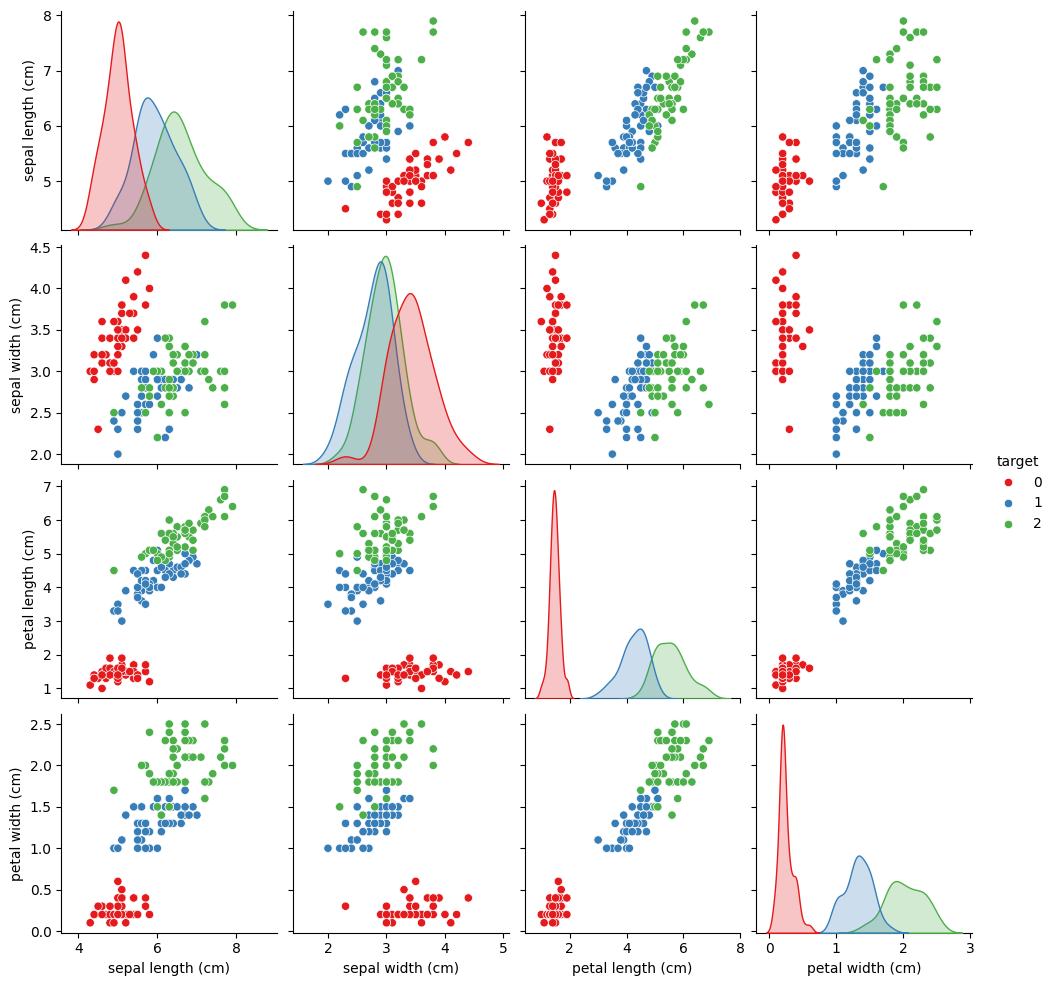

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, hue='target', palette='Set1')
plt.show()

petal length와 petal width 보면 target 0은 다른 두 품종과 완전히 분리된 성향을 보임

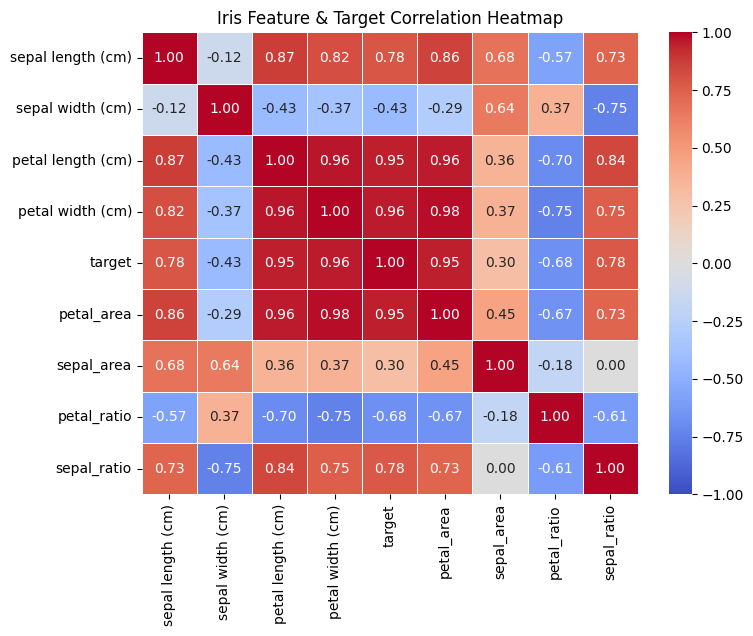

In [48]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Iris Feature & Target Correlation Heatmap')
plt.show()

petal length(cm)와 petal width(cm)가 target과 매우 강한 양의 상관관계를 가지며 sepal width(cm)는 음의 상관관계를 보임을 알 수 있음

# 이상치 확인

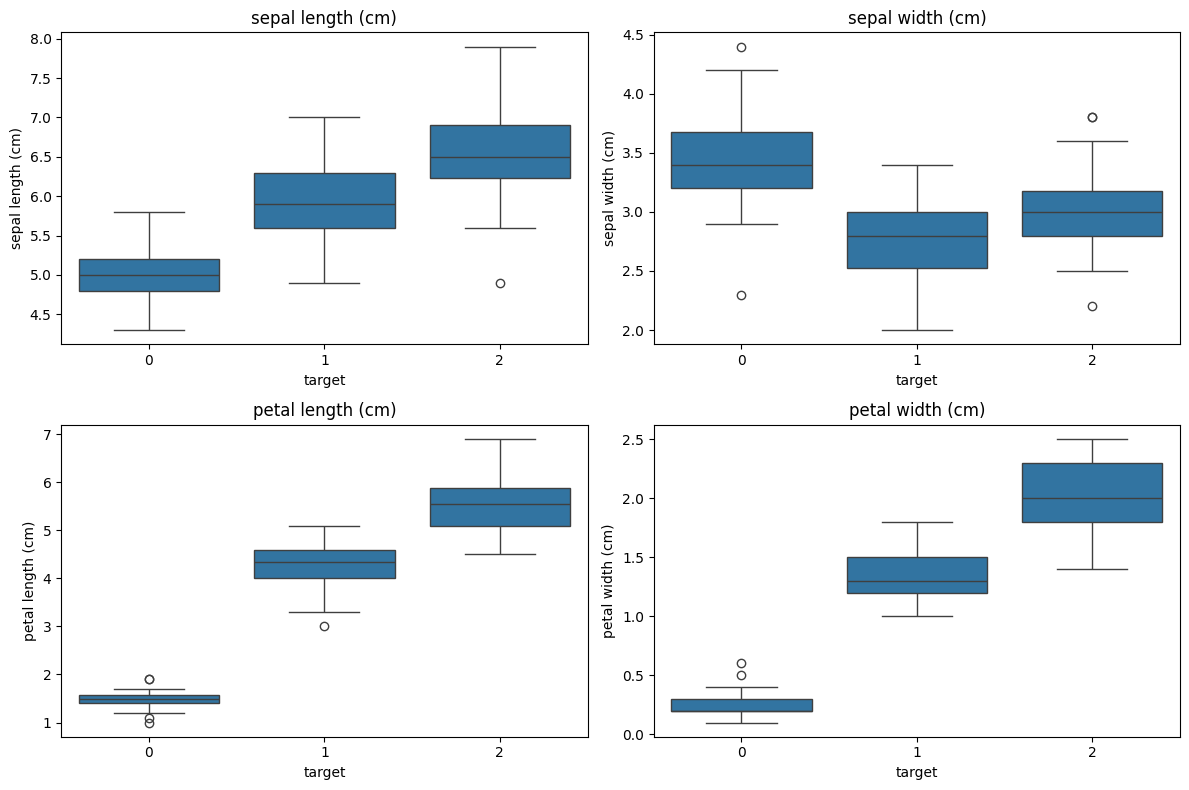

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for idx, col in enumerate(iris.feature_names):
  row, c = divmod(idx, 2)
  sns.boxplot(x='target', y=col, data=df, ax=axes[row, c])
  axes[row, c].set_title(col)

plt.tight_layout()
plt.show()

**이상치 확인 및 처리 근거**


*   박스플롯 확인 결과  `sepal width (cm)` 등에서 IQR 범위를 벗어나는 소수의 이상치 관측됨
*   그러나 해당 값들은 입력 및 측정 오류가 아니라 실제 붓꽃 개체 간의 자연스러운 생물학적 편차 범위 내에 있으며 전체 데이터가 150개로 표본 수가 적어 데이터를 임의로 제거할 경우 정보 손실 및 과적합 위험 있음
*   또한 후속 단계에서 표준화를 적용해 극단값의 스케일 영향을 완화하므로 별도 제거 없이 **전체 데이터를 유지** 함



# 파생 변수 구하기

In [26]:
# 면적
df['petal_area'] = df['petal length (cm)'] * df['petal width (cm)']
df['sepal_area'] = df['sepal length (cm)'] * df['sepal width (cm)']

# 비율
df['petal_ratio'] = df['petal length (cm)'] / df['petal width (cm)']
df['sepal_ratio'] = df['sepal length (cm)'] / df['sepal width (cm)']

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,petal_area,sepal_area,petal_ratio,sepal_ratio
0,5.1,3.5,1.4,0.2,0,0.28,17.85,7.0,1.457143
1,4.9,3.0,1.4,0.2,0,0.28,14.70,7.0,1.633333
2,4.7,3.2,1.3,0.2,0,0.26,15.04,6.5,1.468750
3,4.6,3.1,1.5,0.2,0,0.30,14.26,7.5,1.483871
4,5.0,3.6,1.4,0.2,0,0.28,18.00,7.0,1.388889


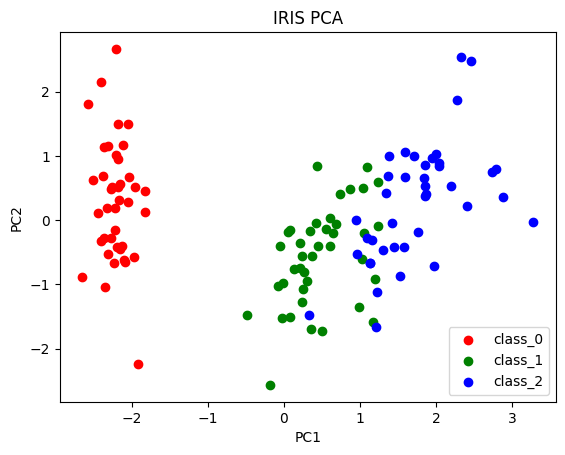

설명된 분산 비율: [0.727 0.231]
총 설명력: 0.957


In [27]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X2D = pca.fit_transform(X_train_s)

colors = ['red', 'green', 'blue']
for i, j in enumerate(np.unique(y_train)):
  plt.scatter(X2D[y_train == j, 0], X2D[y_train == j, 1],
              color = colors[i], label = f'class_{j}')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('IRIS PCA')
plt.legend()
plt.show()

print('설명된 분산 비율:', pca.explained_variance_ratio_.round(3))
print('총 설명력:', pca.explained_variance_ratio_.sum().round(3))

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

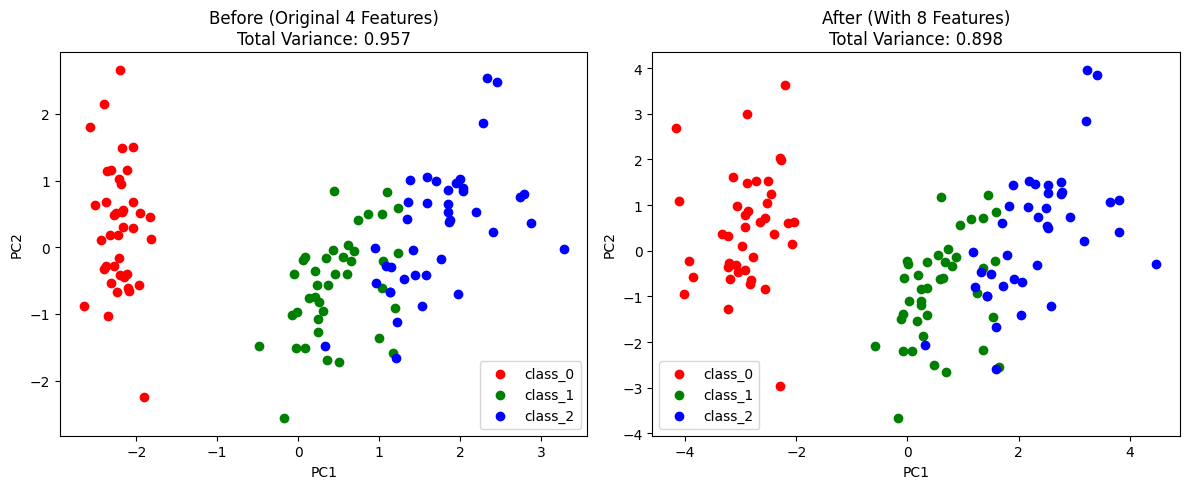

[파생 변수 포함 전 (4개 특성)]
설명된 분산 비율: [0.727 0.231] | 총 설명력: 0.957

[파생 변수 포함 후 (8개 특성)]
설명된 분산 비율: [0.654 0.244] | 총 설명력: 0.898


In [45]:
X_feat = df.drop(columns=['target'])
y_feat = df['target']

X_train_f, X_val_f, y_train_f, y_val_f = train_test_split(
    X_feat, y_feat, test_size=0.2, stratify=y_feat, random_state=42
)

X_train_f_s = (X_train_f - X_train_f.mean(axis=0)) / X_train_f.std(axis=0)

pca_feat  = PCA(n_components=2)
X2D_feat = pca_feat.fit_transform(X_train_f_s)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ['red', 'green', 'blue']

for i, j in enumerate(np.unique(y_train)):
    axes[0].scatter(X2D[y_train == j, 0], X2D[y_train == j, 1], color=colors[i], label=f'class_{j}')
axes[0].set_title(f'Before (Original 4 Features)\nTotal Variance: {pca.explained_variance_ratio_.sum():.3f}')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

for i, j in enumerate(np.unique(y_train_f)):
    axes[1].scatter(X2D_feat[y_train_f == j, 0], X2D_feat[y_train_f == j, 1], color=colors[i], label=f'class_{j}')
axes[1].set_title(f'After (With 8 Features)\nTotal Variance: {pca_feat.explained_variance_ratio_.sum():.3f}')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend()

plt.tight_layout()
plt.show()

print("[파생 변수 포함 전 (4개 특성)]")
print("설명된 분산 비율:", pca.explained_variance_ratio_.round(3), "| 총 설명력:", pca.explained_variance_ratio_.sum().round(3))

print("\n[파생 변수 포함 후 (8개 특성)]")
print("설명된 분산 비율:", pca_feat.explained_variance_ratio_.round(3), "| 총 설명력:", pca_feat.explained_variance_ratio_.sum().round(3))

# **Titanic 데이터셋**

In [28]:
import seaborn as sns
titanic = sns.load_dataset('titanic')

In [29]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


891개의 index가 있다는데 보면 891개를 못채운 non-null count가 있는 것으로 보아 null값을 가지고 있음을 확인

In [30]:
titanic.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


데이터 속성값의 이상 여부 확인

<Axes: >

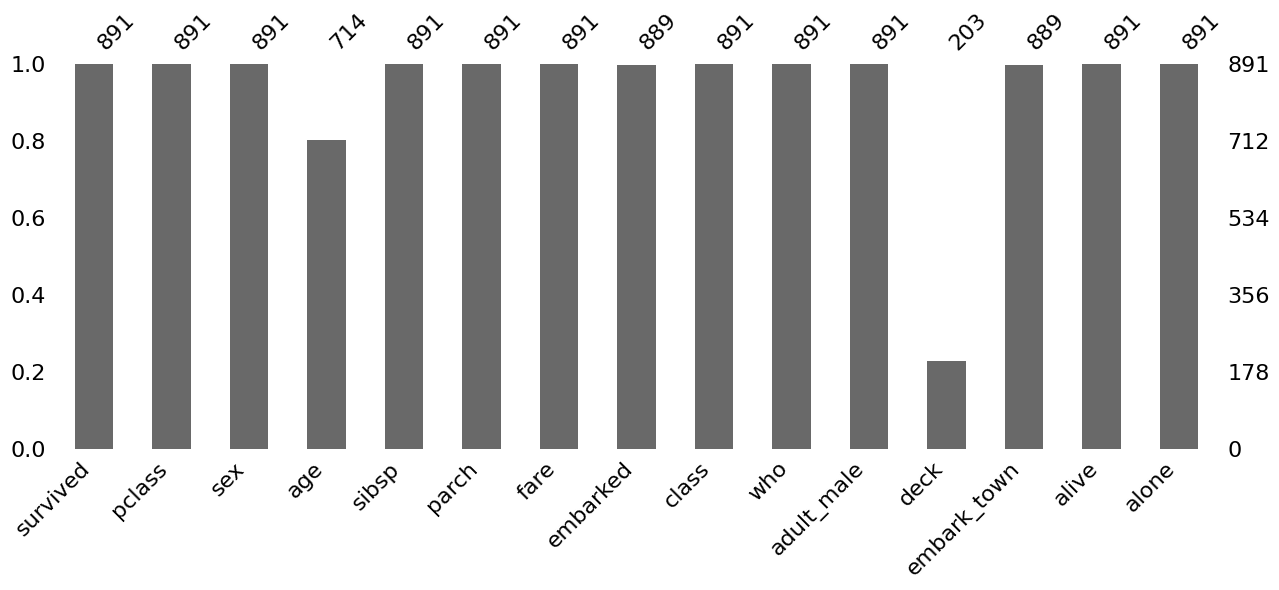

In [31]:
import missingno as msno
msno.bar(titanic, figsize=(15, 5))

# 생존한 인원 확인

In [32]:
titanic['survived'].value_counts()

,count
survived,
0,549
1,342


#최소 전처리

In [33]:
titanic['age'] = titanic['age'].fillna(titanic['age'].median())
titanic['age'].isnull().sum()

np.int64(0)

중간값으로 채운 이유가 이상치가 있을 수 있어서 평균값보단 중앙값으로 잡는 것이 좋다고 판단

In [34]:
titanic['sex'] = titanic['sex'].map({'male': 0, 'female': 1})

성별의 dtye이 object여서 나중에 계산하기 위해 미리 숫자로 변경

In [35]:
titanic.groupby('sex').mean(numeric_only=True)

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
sex,,,,,,,,
0,0.188908,2.389948,30.140676,0.429809,0.235702,25.523893,0.930676,0.712305
1,0.742038,2.159236,27.929936,0.694268,0.649682,44.479818,0.000000,0.401274


1(female)인 경우가 생존률이 더 높음을 확인

           count      mean
age_group                 
Under 10      62  0.612903
10s          102  0.401961
20s          397  0.324937
30s          167  0.437126
40s           89  0.382022
50s           48  0.416667
60+           26  0.269231


/tmp/ipykernel_1264/821566064.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='age_group', y='survived', data=titanic, errorbar=None, palette='Blues_d')


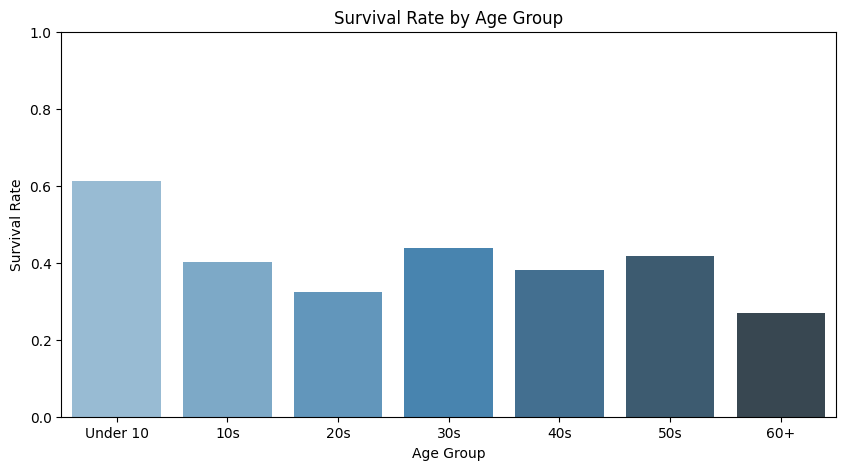

In [47]:
bins = [0, 10, 20, 30, 40, 50, 60, 100]
labels = ['Under 10', '10s', '20s', '30s', '40s', '50s', '60+']

titanic['age_group'] = pd.cut(titanic['age'], bins=bins, labels=labels, right=False)

print(titanic.groupby('age_group', observed=False)['survived'].agg(['count', 'mean']))

plt.figure(figsize=(10, 5))
sns.barplot(x='age_group', y='survived', data=titanic, errorbar=None, palette='Blues_d')
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

승객 연령대별 생존 평균 시각화

가장 많은 결측치를 가진 deck columns 처리.

null -> unknown으로 변환 후 get_dummies를 통해 원핫인코딩 진행

In [37]:
import pandas as pd

titanic['deck'] = titanic['deck'].cat.add_categories('Unknown').fillna('Unknown')

titanic = pd.get_dummies(titanic, columns=['deck'], dtype=int)

titanic.filter(like='deck_').head()

,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_Unknown
0,0,0,0,0,0,0,0,1
1,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,1
3,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,1


중복 의미 컬럼 삭제


*   class - pclass
*   emark_town - embarked
*   who, adult_male - sex + age
*   alive - survivied



In [38]:
drop_cols = ['class', 'embark_town', 'who', 'adult_male', 'alive']
titanic = titanic.drop(columns=drop_cols, errors='ignore')

embarked는 결측치가 2개뿐이여서 최빈값인 S로 채운 뒤 원 핫 인코딩 진행

In [39]:
titanic['embarked'] = titanic['embarked'].fillna(titanic['embarked'].mode()[0])

titanic = pd.get_dummies(titanic, columns=['embarked'], dtype=int)

titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   survived      891 non-null    int64  
 1   pclass        891 non-null    int64  
 2   sex           891 non-null    int64  
 3   age           891 non-null    float64
 4   sibsp         891 non-null    int64  
 5   parch         891 non-null    int64  
 6   fare          891 non-null    float64
 7   alone         891 non-null    bool   
 8   deck_A        891 non-null    int64  
 9   deck_B        891 non-null    int64  
 10  deck_C        891 non-null    int64  
 11  deck_D        891 non-null    int64  
 12  deck_E        891 non-null    int64  
 13  deck_F        891 non-null    int64  
 14  deck_G        891 non-null    int64  
 15  deck_Unknown  891 non-null    int64  
 16  embarked_C    891 non-null    int64  
 17  embarked_Q    891 non-null    int64  
 18  embarked_S    891 non-null    